In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving web_traffic_analytics_v2.csv to web_traffic_analytics_v2.csv


In [3]:
df = pd.read_csv('web_traffic_analytics_v2.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,SessionID,Date,LandingPage,Source,Campaign,DeviceCategory,Region,SessionDurationSec,PageViews,StartedRegistration,Registered,Bounced
0,SESS-500001,2026-02-15,/,Email,none,Mobile,Delhi,243,3,Yes,No,No
1,SESS-500002,2026-06-03,/,Direct,none,Mobile,Karnataka,268,4,No,No,No
2,SESS-500003,2026-04-14,/register,Google Organic,starter,Desktop,Telangana,360,3,Yes,Yes,No
3,SESS-500004,2026-03-31,/register,Email,campus,Desktop,Maharashtra,282,5,Yes,Yes,No
4,SESS-500005,2026-04-24,/programs,Direct,none,Mobile,Tamil Nadu,232,2,No,No,No


In [5]:
print("Dataset Shape:", df.shape)

Dataset Shape: (900, 12)


In [6]:
print(df.columns.tolist())

['SessionID', 'Date', 'LandingPage', 'Source', 'Campaign', 'DeviceCategory', 'Region', 'SessionDurationSec', 'PageViews', 'StartedRegistration', 'Registered', 'Bounced']


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   SessionID            900 non-null    object
 1   Date                 900 non-null    object
 2   LandingPage          900 non-null    object
 3   Source               900 non-null    object
 4   Campaign             900 non-null    object
 5   DeviceCategory       900 non-null    object
 6   Region               900 non-null    object
 7   SessionDurationSec   900 non-null    int64 
 8   PageViews            900 non-null    int64 
 9   StartedRegistration  900 non-null    object
 10  Registered           900 non-null    object
 11  Bounced              900 non-null    object
dtypes: int64(2), object(10)
memory usage: 84.5+ KB


In [8]:
df.describe()

,SessionDurationSec,PageViews
count,900.000000,900.000000
mean,243.485556,3.453333
std,140.922421,1.928373
min,4.000000,1.000000
25%,140.000000,2.000000
50%,235.000000,3.000000
75%,335.000000,5.000000
max,766.000000,11.000000


 Data cleaning...

In [9]:
df.isnull().sum()

,0
SessionID,0
Date,0
LandingPage,0
Source,0
Campaign,0
DeviceCategory,0
Region,0
SessionDurationSec,0
PageViews,0
StartedRegistration,0


Checking duplicate records...

In [10]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


Remove Duplicate Records

In [11]:
df = df.drop_duplicates()

print("Duplicates removed successfully!")

Duplicates removed successfully!


Check Duplicate Session IDs

In [12]:
print("Duplicate Session IDs:", df['SessionID'].duplicated().sum())

Duplicate Session IDs: 0


Convert Date Column

In [13]:
df['Date'] = pd.to_datetime(df['Date'])

print(df['Date'].dtype)

datetime64[ns]


In [14]:
print("Traffic Sources:")
print(df['Source'].unique())

print("\nDevice Categories:")
print(df['DeviceCategory'].unique())

print("\nRegistration Status:")
print(df['Registered'].unique())

print("\nBounce Status:")
print(df['Bounced'].unique())

Traffic Sources:
['Email' 'Direct' 'Google Organic' 'Referral' 'LinkedIn' 'Instagram']

Device Categories:
['Mobile' 'Desktop' 'Tablet']

Registration Status:
['No' 'Yes']

Bounce Status:
['No' 'Yes']


In [15]:
print(df[['SessionDurationSec', 'PageViews']].describe())

       SessionDurationSec   PageViews
count          900.000000  900.000000
mean           243.485556    3.453333
std            140.922421    1.928373
min              4.000000    1.000000
25%            140.000000    2.000000
50%            235.000000    3.000000
75%            335.000000    5.000000
max            766.000000   11.000000


In [16]:
print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Final Dataset Shape: (900, 12)

Missing Values:
SessionID              0
Date                   0
LandingPage            0
Source                 0
Campaign               0
DeviceCategory         0
Region                 0
SessionDurationSec     0
PageViews              0
StartedRegistration    0
Registered             0
Bounced                0
dtype: int64

Duplicate Rows:
0

Data Types:
SessionID                      object
Date                   datetime64[ns]
LandingPage                    object
Source                         object
Campaign                       object
DeviceCategory                 object
Region                         object
SessionDurationSec              int64
PageViews                       int64
StartedRegistration            object
Registered                     object
Bounced                        object
dtype: object


**Website Traffic KPI calculation**

In [17]:
total_visitors = df['SessionID'].nunique()

print("Total Website Visitors:", total_visitors)

Total Website Visitors: 900


In [18]:
total_sessions = len(df)

bounced_sessions = (df['Bounced'] == 'Yes').sum()

bounce_rate = (bounced_sessions / total_sessions) * 100

print("Bounce Rate:", round(bounce_rate, 2), "%")

Bounce Rate: 4.89 %


In [19]:
avg_duration = df['SessionDurationSec'].mean()

print("Average Session Duration:", round(avg_duration, 2), "seconds")

Average Session Duration: 243.49 seconds


In [20]:
avg_pageviews = df['PageViews'].mean()

print("Average Page Views:", round(avg_pageviews, 2))

Average Page Views: 3.45


In [21]:
total_registrations = (df['Registered'] == 'Yes').sum()

registration_rate = (total_registrations / total_sessions) * 100

print("Total Registrations:", total_registrations)

print("Registration Rate:", round(registration_rate, 2), "%")

Total Registrations: 166
Registration Rate: 18.44 %


In [22]:
started_registrations = (df['StartedRegistration'] == 'Yes').sum()

start_rate = (started_registrations / total_sessions) * 100

print("Started Registrations:", started_registrations)

print("Registration Start Rate:", round(start_rate, 2), "%")

Started Registrations: 277
Registration Start Rate: 30.78 %


In [23]:
completion_rate = (total_registrations / started_registrations) * 100

print("Registration Completion Rate:", round(completion_rate, 2), "%")

Registration Completion Rate: 59.93 %


In [24]:
kpi_summary = pd.DataFrame({
    'KPI': [
        'Total Website Sessions',
        'Bounce Rate',
        'Average Session Duration',
        'Average Page Views',
        'Total Registrations',
        'Registration Start Rate',
        'Registration Rate',
        'Registration Completion Rate'
    ],

    'Value': [
        total_sessions,
        round(bounce_rate, 2),
        round(avg_duration, 2),
        round(avg_pageviews, 2),
        total_registrations,
        round(start_rate, 2),
        round(registration_rate, 2),
        round(completion_rate, 2)
    ]
})

kpi_summary

,KPI,Value
0,Total Website Sessions,900.00
1,Bounce Rate,4.89
2,Average Session Duration,243.49
3,Average Page Views,3.45
4,Total Registrations,166.00
5,Registration Start Rate,30.78
6,Registration Rate,18.44
7,Registration Completion Rate,59.93


In [25]:
source_traffic = df['Source'].value_counts()

print(source_traffic)

Source
Google Organic    265
Direct            207
Email             127
LinkedIn          123
Instagram          93
Referral           85
Name: count, dtype: int64


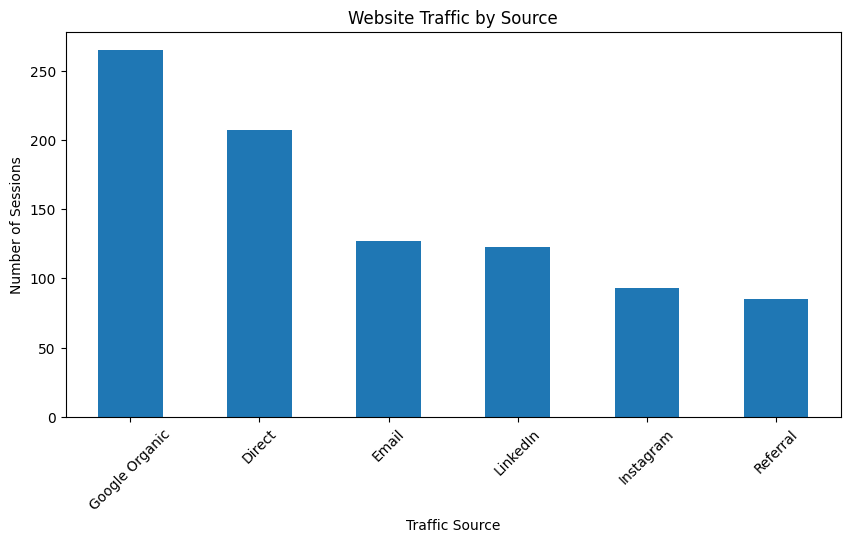

In [26]:
plt.figure(figsize=(10, 5))

source_traffic.plot(kind='bar')

plt.title('Website Traffic by Source')
plt.xlabel('Traffic Source')
plt.ylabel('Number of Sessions')
plt.xticks(rotation=45)

plt.show()

In [27]:
source_registrations = df.groupby('Source')['Registered'].apply(
    lambda x: (x == 'Yes').sum()
)

print(source_registrations)

Source
Direct            36
Email             30
Google Organic    41
Instagram         22
LinkedIn          21
Referral          16
Name: Registered, dtype: int64


In [28]:
source_conversion = df.groupby('Source').agg(
    Total_Sessions=('SessionID', 'nunique'),
    Registrations=('Registered', lambda x: (x == 'Yes').sum())
)

source_conversion['Conversion_Rate'] = (
    source_conversion['Registrations'] /
    source_conversion['Total_Sessions']
) * 100

source_conversion['Conversion_Rate'] = source_conversion[
    'Conversion_Rate'
].round(2)

source_conversion

,Total_Sessions,Registrations,Conversion_Rate
Source,,,
Direct,207,36,17.39
Email,127,30,23.62
Google Organic,265,41,15.47
Instagram,93,22,23.66
LinkedIn,123,21,17.07
Referral,85,16,18.82


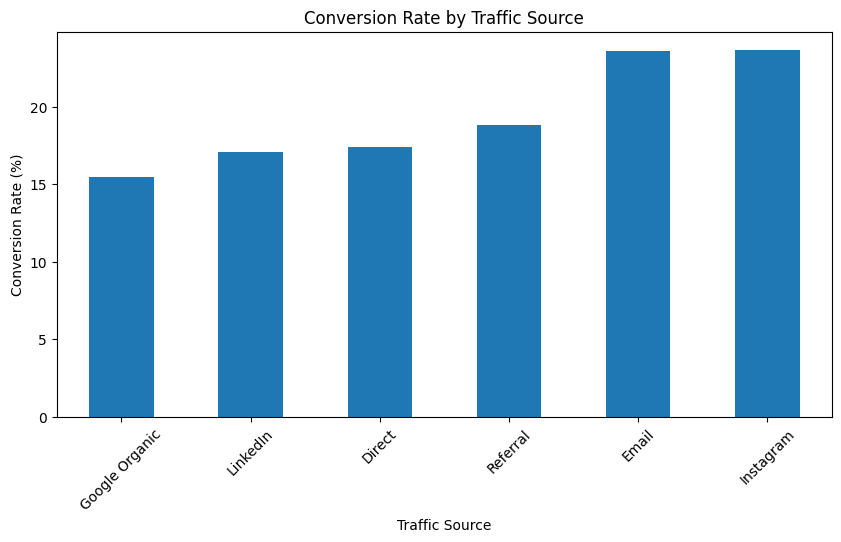

In [29]:
plt.figure(figsize=(10, 5))

source_conversion['Conversion_Rate'].sort_values().plot(
    kind='bar'
)

plt.title('Conversion Rate by Traffic Source')
plt.xlabel('Traffic Source')
plt.ylabel('Conversion Rate (%)')
plt.xticks(rotation=45)

plt.show()

In [30]:
traffic_analysis = df.groupby('Source').agg(
    Total_Sessions=('SessionID', 'nunique'),

    Registrations=('Registered',
                   lambda x: (x == 'Yes').sum()),

    Started_Registrations=('StartedRegistration',
                           lambda x: (x == 'Yes').sum()),

    Bounced_Sessions=('Bounced',
                      lambda x: (x == 'Yes').sum()),

    Avg_Session_Duration=('SessionDurationSec', 'mean'),

    Avg_PageViews=('PageViews', 'mean')
)

traffic_analysis['Conversion_Rate'] = (
    traffic_analysis['Registrations'] /
    traffic_analysis['Total_Sessions']
) * 100

traffic_analysis['Bounce_Rate'] = (
    traffic_analysis['Bounced_Sessions'] /
    traffic_analysis['Total_Sessions']
) * 100

traffic_analysis = traffic_analysis.round(2)

traffic_analysis

,Total_Sessions,Registrations,Started_Registrations,Bounced_Sessions,Avg_Session_Duration,Avg_PageViews,Conversion_Rate,Bounce_Rate
Source,,,,,,,,
Direct,207,36,62,12,228.16,3.32,17.39,5.80
Email,127,30,41,6,243.27,3.51,23.62,4.72
Google Organic,265,41,77,8,257.42,3.51,15.47,3.02
Instagram,93,22,37,4,263.78,3.74,23.66,4.30
LinkedIn,123,21,33,8,238.72,3.38,17.07,6.50
Referral,85,16,27,6,222.36,3.29,18.82,7.06


In [31]:
total_visits = len(df)

print("Total Website Sessions:", total_visits)

Total Website Sessions: 900


In [32]:
registration_started = (
    df['StartedRegistration'] == 'Yes'
).sum()

print("Registration Started:", registration_started)

Registration Started: 277


In [33]:
registration_completed = (
    df['Registered'] == 'Yes'
).sum()

print("Registration Completed:", registration_completed)

Registration Completed: 166


In [34]:
not_started = total_visits - registration_started

print("Visitors Who Did Not Start Registration:", not_started)

Visitors Who Did Not Start Registration: 623


In [35]:
not_completed = registration_started - registration_completed

print("Visitors Who Did Not Complete Registration:", not_completed)

Visitors Who Did Not Complete Registration: 111


In [36]:
visit_to_start = (
    registration_started / total_visits
) * 100

start_to_complete = (
    registration_completed / registration_started
) * 100

overall_conversion = (
    registration_completed / total_visits
) * 100

print("Visit to Registration Start:", round(visit_to_start, 2), "%")

print("Registration Completion Rate:", round(start_to_complete, 2), "%")

print("Overall Conversion Rate:", round(overall_conversion, 2), "%")

Visit to Registration Start: 30.78 %
Registration Completion Rate: 59.93 %
Overall Conversion Rate: 18.44 %


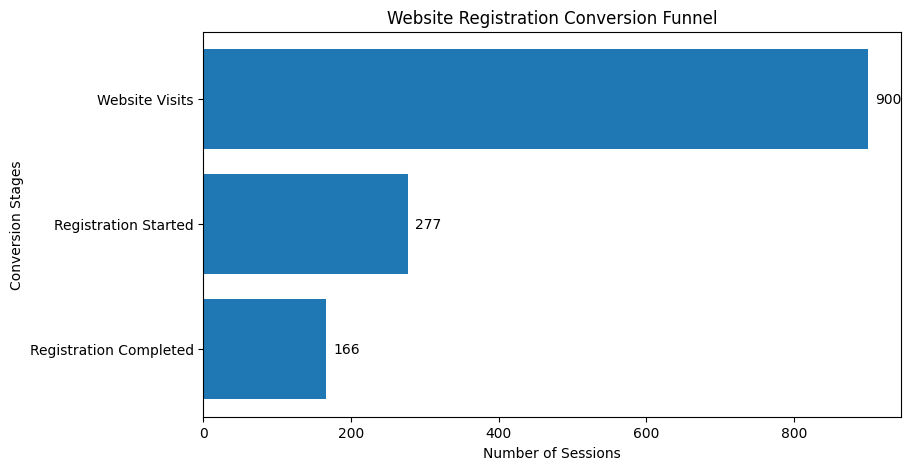

In [37]:
funnel_stages = [
    'Website Visits',
    'Registration Started',
    'Registration Completed'
]

funnel_values = [
    total_visits,
    registration_started,
    registration_completed
]

plt.figure(figsize=(9, 5))

plt.barh(funnel_stages, funnel_values)

plt.title('Website Registration Conversion Funnel')
plt.xlabel('Number of Sessions')
plt.ylabel('Conversion Stages')

for i, value in enumerate(funnel_values):
    plt.text(value + 10, i, str(value), va='center')

plt.gca().invert_yaxis()

plt.show()

In [38]:
funnel_summary = pd.DataFrame({
    'Stage': [
        'Website Visits',
        'Registration Started',
        'Registration Completed'
    ],

    'Sessions': [
        total_visits,
        registration_started,
        registration_completed
    ],

    'Conversion_Percentage': [
        100,
        round(visit_to_start, 2),
        round(overall_conversion, 2)
    ]
})

funnel_summary

,Stage,Sessions,Conversion_Percentage
0,Website Visits,900,100.00
1,Registration Started,277,30.78
2,Registration Completed,166,18.44


In [39]:
device_traffic = df['DeviceCategory'].value_counts()

print(device_traffic)

DeviceCategory
Mobile     593
Desktop    261
Tablet      46
Name: count, dtype: int64


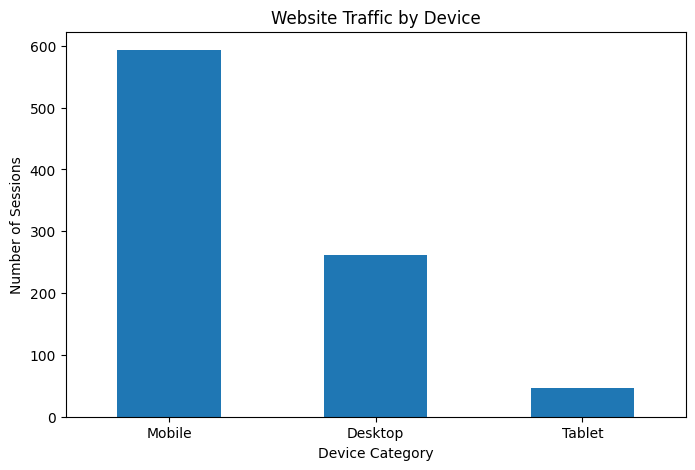

In [40]:
plt.figure(figsize=(8, 5))

device_traffic.plot(kind='bar')

plt.title('Website Traffic by Device')
plt.xlabel('Device Category')
plt.ylabel('Number of Sessions')

plt.xticks(rotation=0)
plt.show()

In [41]:
device_registration = df.groupby('DeviceCategory').agg(
    Total_Sessions=('SessionID', 'nunique'),

    Registrations=('Registered',
                   lambda x: (x == 'Yes').sum())
)

device_registration

,Total_Sessions,Registrations
DeviceCategory,,
Desktop,261,57
Mobile,593,104
Tablet,46,5


In [42]:
device_registration['Conversion_Rate'] = (
    device_registration['Registrations'] /
    device_registration['Total_Sessions']
) * 100

device_registration['Conversion_Rate'] = (
    device_registration['Conversion_Rate'].round(2)
)

device_registration

,Total_Sessions,Registrations,Conversion_Rate
DeviceCategory,,,
Desktop,261,57,21.84
Mobile,593,104,17.54
Tablet,46,5,10.87


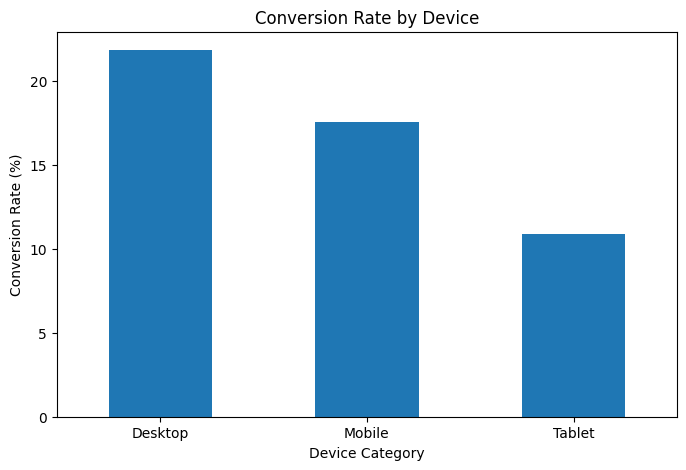

In [43]:
plt.figure(figsize=(8, 5))

device_registration['Conversion_Rate'].plot(kind='bar')

plt.title('Conversion Rate by Device')
plt.xlabel('Device Category')
plt.ylabel('Conversion Rate (%)')

plt.xticks(rotation=0)
plt.show()

In [44]:
landing_traffic = df['LandingPage'].value_counts()

print(landing_traffic)

LandingPage
/            161
/programs    161
/register    151
/login       144
/faq         144
/verify      139
Name: count, dtype: int64


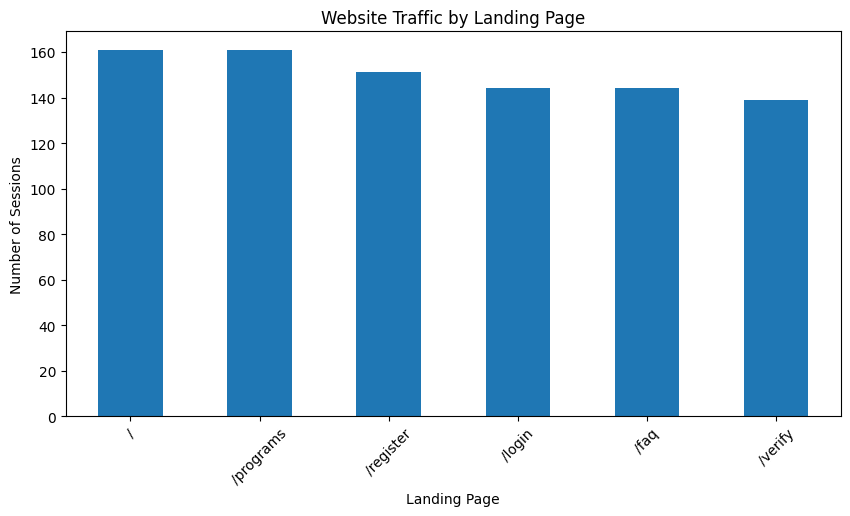

In [45]:
plt.figure(figsize=(10, 5))

landing_traffic.plot(kind='bar')

plt.title('Website Traffic by Landing Page')
plt.xlabel('Landing Page')
plt.ylabel('Number of Sessions')

plt.xticks(rotation=45)
plt.show()

In [46]:
landing_analysis = df.groupby('LandingPage').agg(
    Total_Sessions=('SessionID', 'nunique'),

    Registrations=('Registered',
                   lambda x: (x == 'Yes').sum()),

    Avg_Duration=('SessionDurationSec', 'mean'),

    Avg_PageViews=('PageViews', 'mean')
)

landing_analysis

,Total_Sessions,Registrations,Avg_Duration,Avg_PageViews
LandingPage,,,,
/,161,21,254.906832,3.534161
/faq,144,26,224.826389,3.222222
/login,144,33,247.701389,3.625000
/programs,161,29,256.062112,3.608696
/register,151,29,235.860927,3.337748
/verify,139,28,238.935252,3.366906


In [47]:
landing_analysis['Conversion_Rate'] = (
    landing_analysis['Registrations'] /
    landing_analysis['Total_Sessions']
) * 100

landing_analysis = landing_analysis.round(2)

landing_analysis

,Total_Sessions,Registrations,Avg_Duration,Avg_PageViews,Conversion_Rate
LandingPage,,,,,
/,161,21,254.91,3.53,13.04
/faq,144,26,224.83,3.22,18.06
/login,144,33,247.70,3.62,22.92
/programs,161,29,256.06,3.61,18.01
/register,151,29,235.86,3.34,19.21
/verify,139,28,238.94,3.37,20.14


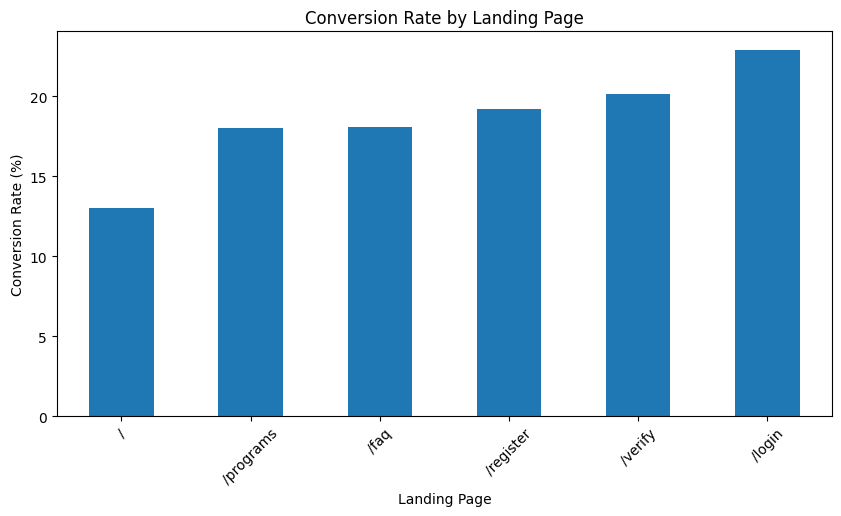

In [48]:
plt.figure(figsize=(10, 5))

landing_analysis['Conversion_Rate'].sort_values().plot(
    kind='bar'
)

plt.title('Conversion Rate by Landing Page')
plt.xlabel('Landing Page')
plt.ylabel('Conversion Rate (%)')

plt.xticks(rotation=45)
plt.show()

In [49]:
best_device = device_registration['Conversion_Rate'].idxmax()

best_landing_page = landing_analysis['Conversion_Rate'].idxmax()

print("Best Performing Device:", best_device)

print("Best Performing Landing Page:", best_landing_page)

Best Performing Device: Desktop
Best Performing Landing Page: /login


In [50]:
df['Year'] = df['Date'].dt.year

df['Month'] = df['Date'].dt.month

df['Day'] = df['Date'].dt.day

df['Day_Name'] = df['Date'].dt.day_name()

df.head()

,SessionID,Date,LandingPage,Source,Campaign,DeviceCategory,Region,SessionDurationSec,PageViews,StartedRegistration,Registered,Bounced,Year,Month,Day,Day_Name
0,SESS-500001,2026-02-15,/,Email,none,Mobile,Delhi,243,3,Yes,No,No,2026,2,15,Sunday
1,SESS-500002,2026-06-03,/,Direct,none,Mobile,Karnataka,268,4,No,No,No,2026,6,3,Wednesday
2,SESS-500003,2026-04-14,/register,Google Organic,starter,Desktop,Telangana,360,3,Yes,Yes,No,2026,4,14,Tuesday
3,SESS-500004,2026-03-31,/register,Email,campus,Desktop,Maharashtra,282,5,Yes,Yes,No,2026,3,31,Tuesday
4,SESS-500005,2026-04-24,/programs,Direct,none,Mobile,Tamil Nadu,232,2,No,No,No,2026,4,24,Friday


In [51]:
daily_traffic = df.groupby('Date')['SessionID'].nunique()

print(daily_traffic)

Date
2026-01-01    5
2026-01-02    4
2026-01-03    2
2026-01-04    3
2026-01-05    5
             ..
2026-08-24    9
2026-08-25    3
2026-08-26    5
2026-08-27    5
2026-08-28    2
Name: SessionID, Length: 237, dtype: int64


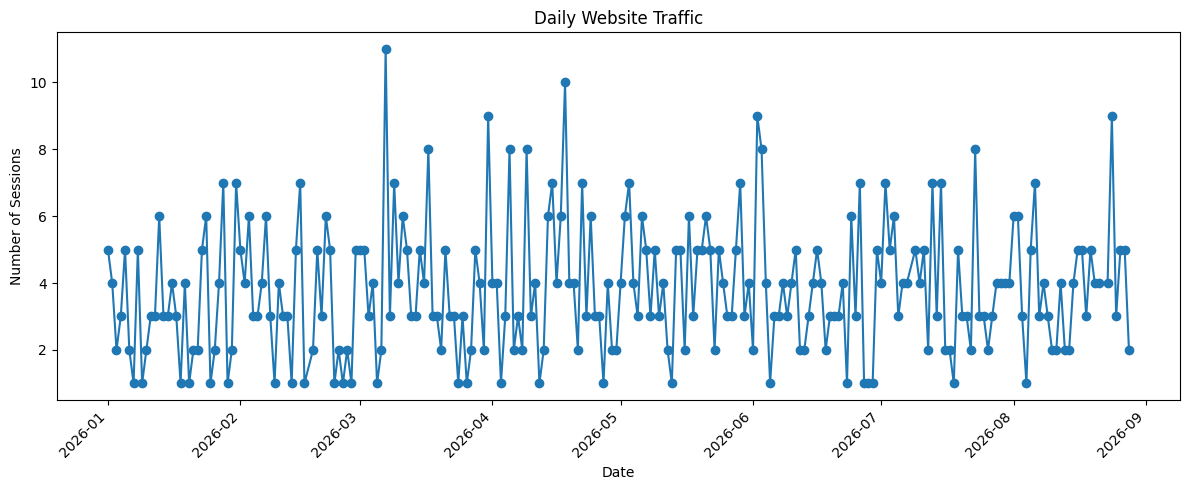

In [52]:
plt.figure(figsize=(12, 5))

daily_traffic.plot(kind='line', marker='o')

plt.title('Daily Website Traffic')
plt.xlabel('Date')
plt.ylabel('Number of Sessions')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [53]:
weekday_traffic = df.groupby('Day_Name')['SessionID'].nunique()

weekday_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

weekday_traffic = weekday_traffic.reindex(weekday_order)

print(weekday_traffic)

Day_Name
Monday       117
Tuesday      124
Wednesday    133
Thursday     139
Friday       116
Saturday     142
Sunday       129
Name: SessionID, dtype: int64


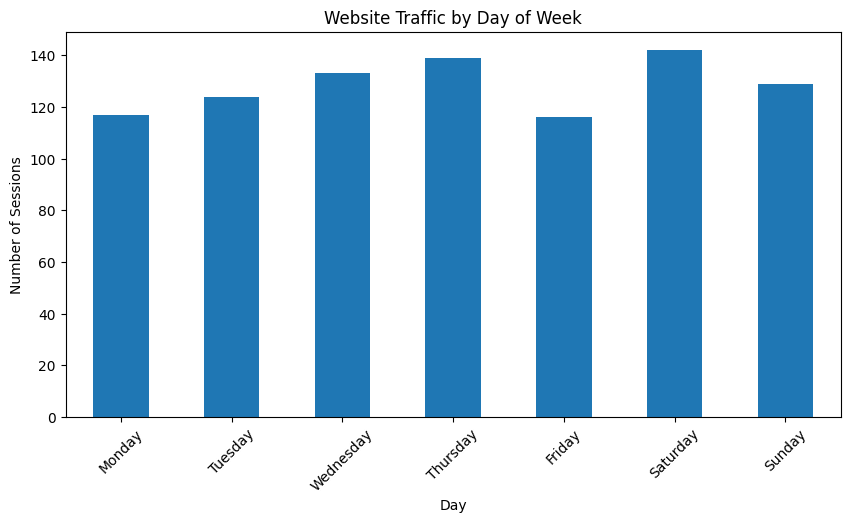

In [54]:
plt.figure(figsize=(10, 5))

weekday_traffic.plot(kind='bar')

plt.title('Website Traffic by Day of Week')
plt.xlabel('Day')
plt.ylabel('Number of Sessions')

plt.xticks(rotation=45)

plt.show()

In [55]:
monthly_traffic = df.groupby('Month')['SessionID'].nunique()

print(monthly_traffic)

Month
1    100
2     92
3    125
4    119
5    131
6    106
7    119
8    108
Name: SessionID, dtype: int64


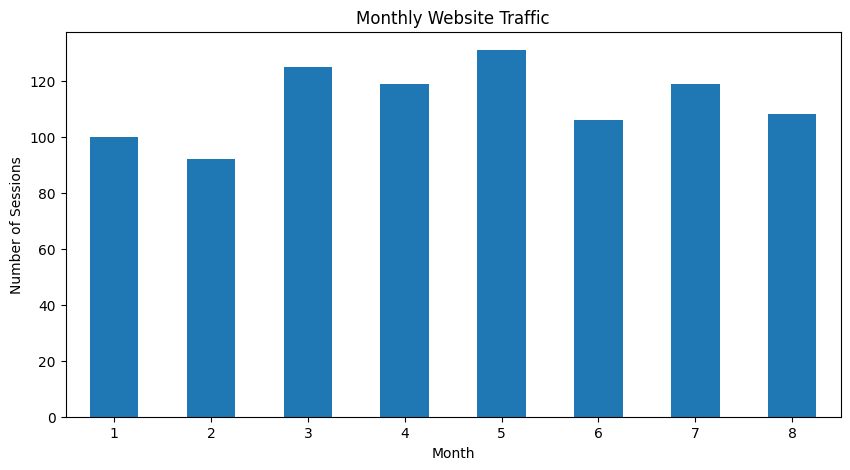

In [56]:
plt.figure(figsize=(10, 5))

monthly_traffic.plot(kind='bar')

plt.title('Monthly Website Traffic')
plt.xlabel('Month')
plt.ylabel('Number of Sessions')

plt.xticks(rotation=0)

plt.show()

In [57]:
monthly_registrations = df.groupby('Month')['Registered'].apply(
    lambda x: (x == 'Yes').sum()
)

print(monthly_registrations)

Month
1    21
2    10
3    28
4    19
5    20
6    14
7    23
8    31
Name: Registered, dtype: int64


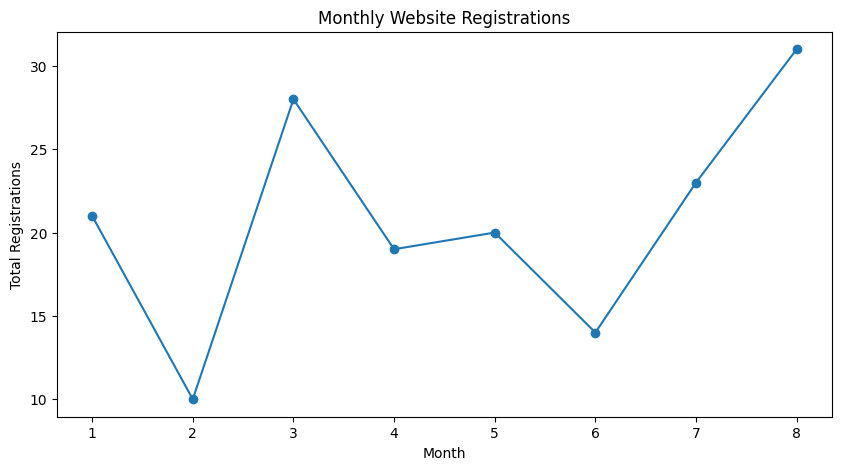

In [58]:
plt.figure(figsize=(10, 5))

monthly_registrations.plot(kind='line', marker='o')

plt.title('Monthly Website Registrations')
plt.xlabel('Month')
plt.ylabel('Total Registrations')

plt.show()

In [59]:
best_day = weekday_traffic.idxmax()

highest_day_traffic = weekday_traffic.max()

print("Highest Traffic Day:", best_day)

print("Number of Sessions:", highest_day_traffic)

Highest Traffic Day: Saturday
Number of Sessions: 142


In [60]:
best_month = monthly_traffic.idxmax()

highest_month_traffic = monthly_traffic.max()

print("Highest Traffic Month:", best_month)

print("Number of Sessions:", highest_month_traffic)

Highest Traffic Month: 5
Number of Sessions: 131


In [61]:
monthly_analysis = df.groupby('Month').agg(
    Total_Sessions=('SessionID', 'nunique'),

    Registrations=('Registered',
                   lambda x: (x == 'Yes').sum()),

    Avg_Session_Duration=('SessionDurationSec', 'mean'),

    Avg_PageViews=('PageViews', 'mean')
)

monthly_analysis['Conversion_Rate'] = (
    monthly_analysis['Registrations'] /
    monthly_analysis['Total_Sessions']
) * 100

monthly_analysis = monthly_analysis.round(2)

monthly_analysis

,Total_Sessions,Registrations,Avg_Session_Duration,Avg_PageViews,Conversion_Rate
Month,,,,,
1,100,21,237.07,3.41,21.00
2,92,10,212.91,3.14,10.87
3,125,28,272.25,3.81,22.40
4,119,19,246.66,3.34,15.97
5,131,20,234.55,3.29,15.27
6,106,14,236.54,3.48,13.21
7,119,23,245.96,3.38,19.33
8,108,31,253.61,3.72,28.70


In [62]:
duration_analysis = df.groupby('Registered')['SessionDurationSec'].mean()

print(duration_analysis)

Registered
No     232.400545
Yes    292.500000
Name: SessionDurationSec, dtype: float64


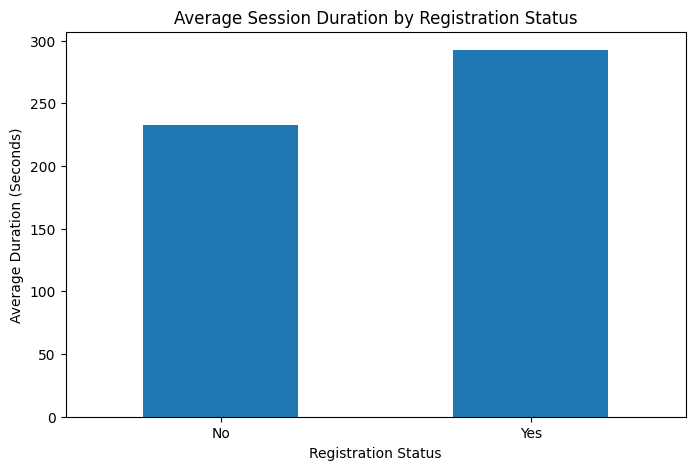

In [63]:
plt.figure(figsize=(8, 5))

duration_analysis.plot(kind='bar')

plt.title('Average Session Duration by Registration Status')
plt.xlabel('Registration Status')
plt.ylabel('Average Duration (Seconds)')

plt.xticks(rotation=0)
plt.show()

In [64]:
pageview_analysis = df.groupby('Registered')['PageViews'].mean()

print(pageview_analysis)

Registered
No     3.290191
Yes    4.174699
Name: PageViews, dtype: float64


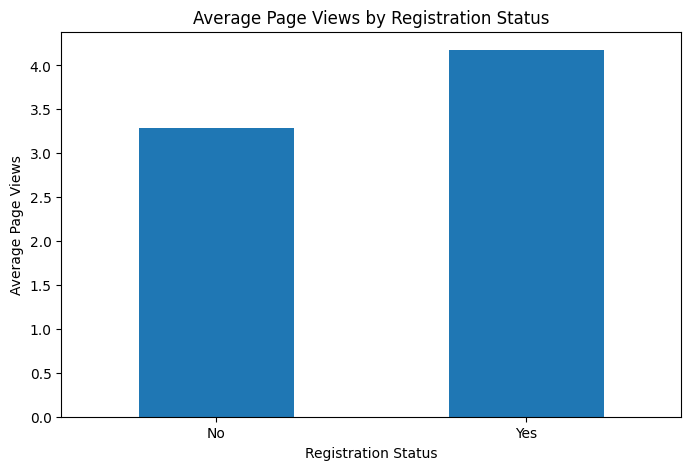

In [65]:
plt.figure(figsize=(8, 5))

pageview_analysis.plot(kind='bar')

plt.title('Average Page Views by Registration Status')
plt.xlabel('Registration Status')
plt.ylabel('Average Page Views')

plt.xticks(rotation=0)
plt.show()

In [66]:
device_bounce = df.groupby('DeviceCategory').agg(
    Total_Sessions=('SessionID', 'nunique'),

    Bounced_Sessions=('Bounced',
                      lambda x: (x == 'Yes').sum())
)

device_bounce['Bounce_Rate'] = (
    device_bounce['Bounced_Sessions'] /
    device_bounce['Total_Sessions']
) * 100

device_bounce = device_bounce.round(2)

device_bounce

,Total_Sessions,Bounced_Sessions,Bounce_Rate
DeviceCategory,,,
Desktop,261,12,4.60
Mobile,593,30,5.06
Tablet,46,2,4.35


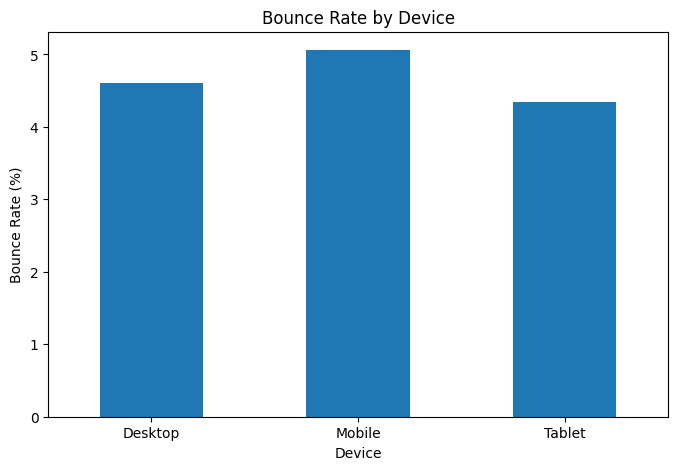

In [67]:
plt.figure(figsize=(8, 5))

device_bounce['Bounce_Rate'].plot(kind='bar')

plt.title('Bounce Rate by Device')
plt.xlabel('Device')
plt.ylabel('Bounce Rate (%)')

plt.xticks(rotation=0)
plt.show()

In [68]:
numeric_data = df[
    ['SessionDurationSec', 'PageViews']
]

correlation = numeric_data.corr()

print(correlation)

                    SessionDurationSec  PageViews
SessionDurationSec            1.000000   0.771956
PageViews                     0.771956   1.000000


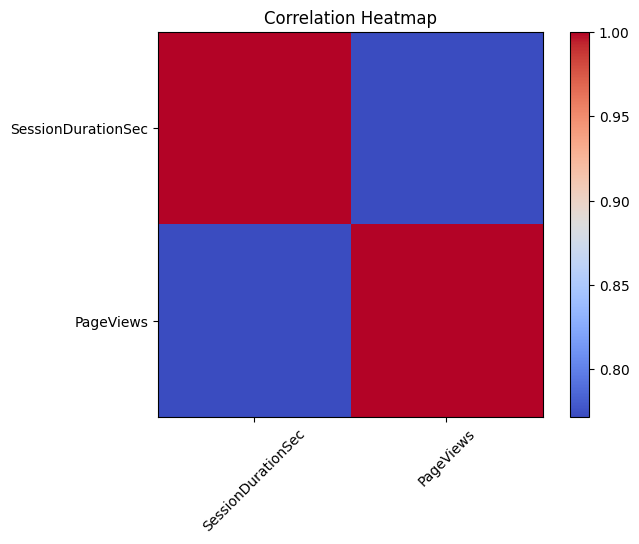

In [69]:
plt.figure(figsize=(7, 5))

plt.imshow(correlation, cmap='coolwarm')

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title('Correlation Heatmap')

plt.show()

In [70]:
visitor_behavior = df.groupby('Registered').agg(
    Total_Sessions=('SessionID', 'nunique'),

    Avg_Duration=('SessionDurationSec', 'mean'),

    Avg_PageViews=('PageViews', 'mean'),

    Bounce_Count=('Bounced',
                  lambda x: (x == 'Yes').sum())
)

visitor_behavior = visitor_behavior.round(2)

visitor_behavior

,Total_Sessions,Avg_Duration,Avg_PageViews,Bounce_Count
Registered,,,,
No,734,232.4,3.29,42
Yes,166,292.5,4.17,2


In [71]:
print("Average Duration by Registration:")
print(duration_analysis)

print("\nAverage Page Views by Registration:")
print(pageview_analysis)

print("\nDevice Bounce Analysis:")
print(device_bounce)

print("\nVisitor Behaviour:")
print(visitor_behavior)

Average Duration by Registration:
Registered
No     232.400545
Yes    292.500000
Name: SessionDurationSec, dtype: float64

Average Page Views by Registration:
Registered
No     3.290191
Yes    4.174699
Name: PageViews, dtype: float64

Device Bounce Analysis:
                Total_Sessions  Bounced_Sessions  Bounce_Rate
DeviceCategory                                               
Desktop                    261                12         4.60
Mobile                     593                30         5.06
Tablet                      46                 2         4.35

Visitor Behaviour:
            Total_Sessions  Avg_Duration  Avg_PageViews  Bounce_Count
Registered                                                           
No                     734         232.4           3.29            42
Yes                    166         292.5           4.17             2
